In [1]:
# useful to autoreload the module without restarting the kernel
%load_ext autoreload
%autoreload 2

In [2]:
from mppi import Parsers as P, Optics as O
from mppi.Utilities import Constants as Const
from mppi.Utilities import Utils
import matplotlib.pyplot as plt
import numpy as np
import os, re

# Transient absorption from the non-linear $\chi$ and comparison with the RT runs

Reconstruction of the pump induced change $\delta\chi^{neq}$ of the probe response from the equilibrium non-linear
susceptibilities extracted in `NL-Chi_Analysis.ipynb`, and comparison with the direct real-time pump-probe simulations of
D. Sangalli (kx16, one run for each pump-probe delay, in `Davide_data/`).

Structure: the RT pump-probe simulations of D. Sangalli (IP runs: reading, spectra vs the delay, 2D maps), the equilibrium
susceptibilities from `yambo_nl`, the theory and the reconstruction of $\delta\chi^{neq}$.

The formula for $\delta\chi^{neq}$ (third order terms only), its implementation (`dchi_neq`) and the approximations
are described in the last section.

The susceptibilities are taken from the kx16 runs with damping 0.3 eV (the grid of the RT runs): sine (probe only) and
P&p (pump 1e6 kW/m$^2$), 155 probe frequencies 10.000-24.919 eV with step $\omega_P/16$, so the shifted grids
$\omega\pm 2\omega_P$ fall exactly on the probe grid.

## RT pump-probe simulations of D. Sangalli (kx16, IP)

Folder `Davide_data/20250312_Report_simulations_data_kx16_ball`, runs `td-ip-ber_..._1-15b_...`: independent particles,
bands 1-15, Berry phase coupling, yambo 5.3, CRANKNIC with time step 3 as, 40 fs, no dephasing. One run for each probe
time $t_p$ (folder `delta<t_p>fs`): DELTA probe along x at $t_p$ and QSFIELD pump (phase 90°, `5SIGMA`) at 1.56 eV along
x, 6e9 kW/cm$^2$, $\sigma$ = 3.219 fs (FWHM of the envelope 7.58 fs). The file `o-abs_0-50eV_sm0.6eV.YPP-eps_along_E`
contains $\epsilon(\omega)$ computed by `ypp` from the polarization after the probe (columns: energy, Im $\epsilon$
x, y, z, Re $\epsilon$ x, y, z), 0-50 eV, step 0.01 eV, Lorentzian smoothing 0.6 eV. The folder also contains the runs
with the electron-hole interaction (`td-hsex-cv-ber`, bands 3-12), not used here.

Conventions of the plotting script of D. Sangalli (`20250312_Report_simulations_data_kx16.py`), used here:

- delay $\tau = t_p - t_P$ with the pump maximum at $t_P$ = 15.9 fs (yambo puts the center of the envelope at
  $t_{start} + (\pi/\omega_P)\,\mathrm{nint}(5\sigma\omega_P/\pi)$ = 15.909 fs; $t_p$ is read from the header);
- the reference ("Eq.") is the run with the earliest probe ($t_p$ = 5.25 fs, $\tau$ = -10.66 fs, $3.3\sigma$ before the
  pump maximum), and the changes are $\Delta X(\omega,\tau) = X(\omega,\tau) - X(\omega,\tau_{ref})$;
- reflectivity: Fresnel formula of the semi-infinite crystal, angle of incidence $\theta$ from the normal ($\theta$ =
  72° and s polarization in the figures).

In his maps the curve "Neq." of the left panel and the right panel are averages over the delays within 2 fs from
$\tau$ = 0.1 fs, and the left panel shows $-X$ (axis from -1 to 0); here they are taken at a single delay.

In [3]:
import glob
from matplotlib.colors import TwoSlopeNorm

rt_path = 'Davide_data/20250312_Report_simulations_data_kx16_ball'
rt_file = 'o-abs_0-50eV_sm0.6eV.YPP-eps_along_E'

def field_params(fname):
    # (initial time (fs), width (fs), frequency (eV), intensity (kW/cm^2)) of the fields in the header of a ypp file:
    # probe, pump
    hdr = [l for l in open(fname) if l.startswith('#')]
    get = lambda key : [float(l.split(':')[1].split()[0]) for l in hdr if '[FIELDs] '+key in l]
    return list(zip(get('Initial time'),get('Width'),get('Frequency range'),get('Intensity')))

def load_rt_runs(prefix='td-ip-ber', path=rt_path):
    # eps along x for all the probe times of a set of RT runs, sorted by the delay tau = t_p - t_P (fs)
    folders = glob.glob(os.path.join(path,prefix+'*delta*fs*'))
    t_p = np.array([field_params(os.path.join(f,rt_file))[0][0] for f in folders])
    (t_start,sigma,w_P,I_P) = field_params(os.path.join(folders[0],rt_file))[1]
    w = w_P/Const.Planck_reduced_ev_fs                                # rad/fs
    t_P = t_start + np.pi/w*np.rint(w/np.pi*5*sigma)                  # center of the QSFIELD envelope (5SIGMA)
    data = [np.loadtxt(os.path.join(folders[i],rt_file)) for i in np.argsort(t_p)]
    return dict(energy=data[0][:,0], eps=np.array([d[:,4]+1j*d[:,1] for d in data]), tau=np.sort(t_p)-t_P, t_P=t_P,
                pump=dict(freq=w_P,sigma=sigma,intensity=I_P))

def reflectivity(eps, theta=72., pol='s'):
    # Fresnel reflectivity, angle of incidence theta (degrees from the normal)
    c, q = np.cos(np.radians(theta)), np.sqrt(eps - np.sin(np.radians(theta))**2 + 0j)
    r = (c-q)/(c+q) if pol == 's' else (eps*c-q)/(eps*c+q)
    return np.abs(r)**2

def rt_quantity(runs, quantity='Im eps', change=False, relative=False, **kw):
    # Im eps, Re eps or R (n_delays, n_energies), or their change w.r.t. the reference (earliest delay)
    q = {'Im eps':lambda e : e.imag, 'Re eps':lambda e : e.real, 'R':lambda e : reflectivity(e,**kw)}[quantity](runs['eps'])
    if not change: return q
    return (q-q[0])/q[0] if relative else q-q[0]

rt_ip = load_rt_runs()
d = rt_quantity(rt_ip,change=True)
sel = (rt_ip['energy'] > 10) & (rt_ip['energy'] < 30)
print('%d delays, tau %.2f..%.2f fs (t_P = %.3f fs), E %.1f-%.1f eV, pump %s'%(len(rt_ip['tau']),rt_ip['tau'][0],
      rt_ip['tau'][-1],rt_ip['t_P'],rt_ip['energy'][0],rt_ip['energy'][-1],rt_ip['pump']))
print('delays:',np.round(rt_ip['tau'],2))
print('max |Delta Im eps| in 10-30 eV: %.1e (all the delays), %.1e at the last delay (after the pump)'%(
      np.abs(d[:,sel]).max(),np.abs(d[-1,sel]).max()))

62 delays, tau -10.66..8.09 fs (t_P = 15.909 fs), E 0.0-50.0 eV, pump {'freq': 1.56, 'sigma': 3.21892962, 'intensity': 6000000000.0}
delays: [-10.66  -7.16  -6.91  -6.66  -6.41  -6.16  -5.91  -5.66  -5.41  -4.91
  -4.66  -4.41  -4.16  -3.91  -3.66  -3.41  -3.16  -2.91  -2.66  -2.41
  -2.16  -1.91  -1.66  -1.41  -1.16  -0.91  -0.66  -0.41  -0.16   0.09
   0.34   0.59   0.84   1.09   1.34   1.59   1.84   2.09   2.34   2.59
   2.84   3.09   3.34   3.59   3.84   4.09   4.34   4.59   4.84   5.09
   5.34   5.59   5.84   6.09   6.34   6.59   6.84   7.09   7.34   7.59
   7.84   8.09]
max |Delta Im eps| in 10-30 eV: 1.8e-01 (all the delays), 8.7e-04 at the last delay (after the pump)


Spectra at selected delays (the nearest available ones): Im $\epsilon$ and its change w.r.t. the reference.

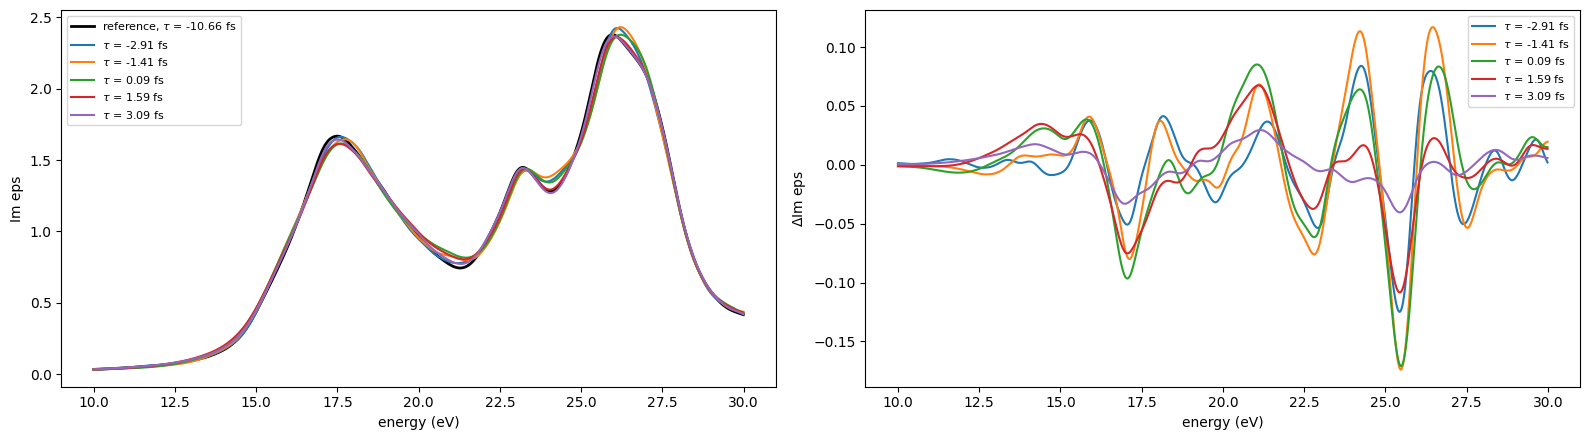

In [4]:
def plot_rt_spectra(runs, taus, quantity='Im eps', change=False, erange=(10,30), ax=None, **kw):
    # spectra (or their changes) at the delays closest to taus (fs)
    if ax is None: ax = plt.subplots(figsize=(10,4.5))[1]
    q = rt_quantity(runs,quantity,change=change,**kw)
    E = runs['energy']
    s = (E >= erange[0]) & (E <= erange[1])
    if not change: ax.plot(E[s],q[0,s],'k',lw=2,label=r'reference, $\tau$ = %.2f fs'%runs['tau'][0])
    for t in taus:
        i = np.argmin(np.abs(runs['tau']-t))
        ax.plot(E[s],q[i,s],label=r'$\tau$ = %.2f fs'%runs['tau'][i])
    ax.set_xlabel('energy (eV)')
    ax.set_ylabel(r'$\Delta$'+quantity if change else quantity)
    ax.legend(fontsize=8)
    return ax

fig,axes = plt.subplots(1,2,figsize=(16,4.5))
plot_rt_spectra(rt_ip,[-3,-1.5,0,1.5,3],ax=axes[0])
plot_rt_spectra(rt_ip,[-3,-1.5,0,1.5,3],change=True,ax=axes[1])
plt.tight_layout()

Maps of the change vs the delay (x) and the probe energy (y), as in the figures of D. Sangalli. With `tau_cut` the
left panel shows the reference and the spectrum at that delay and the right panel the change at that delay. Bottom:
$\Delta R/R$ at 72° (s polarization) in 20-50 eV with the color scale of his figure.

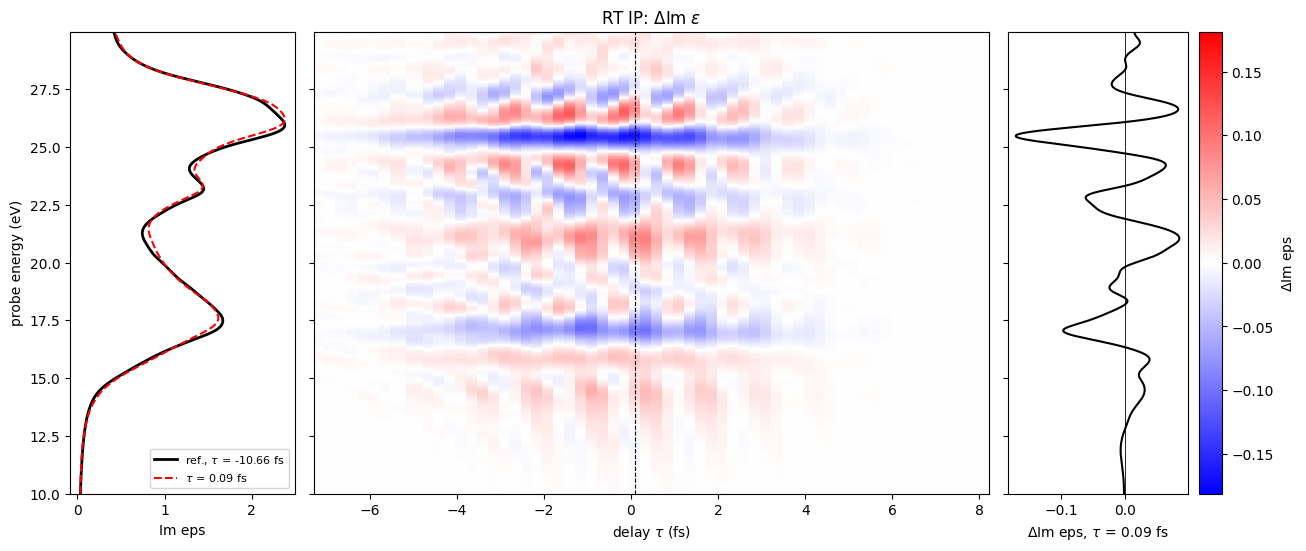

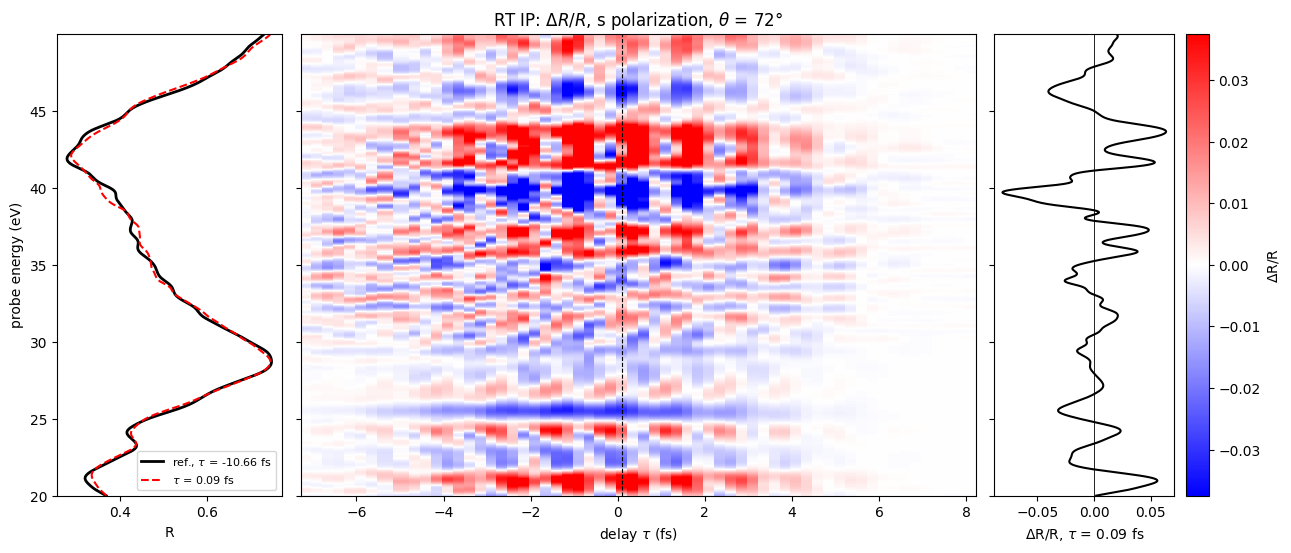

In [5]:
def plot_rt_map(runs, quantity='Im eps', relative=False, erange=(10,30), tau_cut=0., vmax=None, title=None, **kw):
    q = rt_quantity(runs,quantity,**kw)
    d = rt_quantity(runs,quantity,change=True,relative=relative,**kw)
    E, tau = runs['energy'], runs['tau']
    s = (E >= erange[0]) & (E <= erange[1])
    if vmax is None: vmax = np.abs(d[1:,s]).max()
    fig,axes = plt.subplots(1,3,figsize=(15,6),sharey=True,gridspec_kw=dict(width_ratios=[1,3,1],wspace=0.05))
    pc = axes[1].pcolormesh(tau[1:],E[s],d[1:,s].T,cmap='bwr',norm=TwoSlopeNorm(0,-vmax,vmax),shading='nearest')
    lab = r'$\Delta$%s/%s'%(quantity,quantity) if relative else r'$\Delta$%s'%quantity
    fig.colorbar(pc,ax=axes[2],label=lab)
    i = np.argmin(np.abs(tau-tau_cut))
    axes[1].axvline(tau[i],color='k',lw=0.8,ls='--')
    axes[1].set_xlabel(r'delay $\tau$ (fs)')
    axes[1].set_title(title if title else lab)
    axes[0].plot(q[0,s],E[s],'k',lw=2,label=r'ref., $\tau$ = %.2f fs'%tau[0])
    axes[0].plot(q[i,s],E[s],'r--',label=r'$\tau$ = %.2f fs'%tau[i])
    axes[0].set_xlabel(quantity)
    axes[0].set_ylabel('probe energy (eV)')
    axes[0].legend(fontsize=8)
    axes[2].plot(d[i,s],E[s],'k')
    axes[2].axvline(0,color='k',lw=0.6)
    axes[2].set_xlabel(r'%s, $\tau$ = %.2f fs'%(lab,tau[i]))
    return fig,axes

plot_rt_map(rt_ip,'Im eps',title=r'RT IP: $\Delta$Im $\epsilon$')
plot_rt_map(rt_ip,'R',relative=True,theta=72,pol='s',erange=(20,50),vmax=0.0375,
            title=r'RT IP: $\Delta R/R$, s polarization, $\theta$ = 72°');

## Equilibrium susceptibilities (yambo_nl, kx16)

Damping 0.3 eV in the dynamics plus an a posteriori Lorentzian broadening of 0.3 eV (`compute_Xn(broadening=0.3)`, on
the keys linear in the probe): total 0.6 eV, the smoothing of the RT spectra.

In [6]:
run_dir = 'kx16_nb100_NoTr_E100'
name_sine = 'pulse-E1_1e3-nlenrange_10.0-25.016-nlensteps_155-bands_3-6-damp_0.3-sin-nltime_100'
name_Pp = 'Pp-Ep_1e3-EP_1e6-PE_1.55-nlenrange_10.0-25.016-nlensteps_155-bands_3-6-damp_0.3-sin-nltime_100'
data_sine = P.YamboNLDBParser(os.path.join(run_dir,name_sine,'ndb.Nonlinear'),verbose=False)
data_Pp = P.YamboNLDBParser(os.path.join(run_dir,name_Pp,'ndb.Nonlinear'),verbose=False)
freq_mix = O.Xn_frequency_mixing(data_Pp,X_order=(1,2),verbose=False)
broad = 0.3                            # eV, a posteriori broadening: 0.3 + 0.3 = 0.6 eV, the smoothing of the RT spectra
chi_freqmix = freq_mix.compute_Xn(broadening=broad)[0]
chi1_sin = O.Xn_single_frequency(data_sine,X_order=3,verbose=False).compute_Xn(broadening=broad)[0][1]
omega = freq_mix.probe_freqs           # Hartree
freqs = omega*Const.HaToeV
omega_P = freq_mix.pump_freq           # Hartree
EP = data_Pp.Efield2[0]['amplitude']   # au
x11m1 = (chi_freqmix[(1,0)] - chi1_sin)/(EP**2/4)
print('%d probe frequencies %.3f-%.3f eV, step/omega_P = %.4f, pump %.3f eV, E0 pump %.3e au'%(
      len(omega),freqs[0],freqs[-1],(omega[1]-omega[0])/omega_P,omega_P*Const.HaToeV,EP))

155 probe frequencies 10.000-24.919 eV, step/omega_P = 0.0625, pump 1.550 eV, E0 pump 1.194e-04 au


### Correction of the INVINT integrator and equilibrium check

The yambo_nl runs use the INVINT integrator with `NLstep` $dt$ = 0.01 fs, which has two effects (see the MPPI notes in
the CLAUDE.md of the project):

- in the static part of the dynamics a transition of energy $E$ evolves with $E_{eff} = (2\hbar/dt)\arctan(E\,dt/2\hbar)
  < E$, so the resonances of our $\chi$ are red shifted by $\simeq E^3dt^2/12\hbar^2$: 0.04, 0.06, 0.09, 0.13, 0.18 eV
  at 13, 15, 17, 19, 21 eV;
- the fields act with a delay $dt/2$, so every key is multiplied by $e^{i\omega dt/2}$, with $\omega$ the frequency of
  the output polarization: for the key $(1,m)$ at the probe frequency $\omega'$ the delays of the probe and of the pump
  give $e^{i(\omega'+m\omega_P)dt/2}$. The phase is 0.13 rad at 17 eV: it mixes Re $\chi$ into Im $\chi$ and moves the
  absorption edge.

The correction is $\chi_{corr}(\omega) = \chi(\omega_{eff})e^{-i\omega_{eff}dt/2}$ (linear interpolation on the grid),
applied to $\chi^{(1)}$ and to $\delta\chi(\omega)$ at the frequency of the spectrum (the same phase for the three
terms). All the spectra shown below are corrected. The RT runs use CRANKNIC with $dt$ = 3 as (shift $<$ 0.01 eV, phase 0.04 rad at 17 eV, neglected).

Equilibrium check: the earliest delay of the RT runs ($\tau$ = -10.66 fs, pump envelope $\sim10^{-5}$) is the
equilibrium spectrum of the RT setup (IP, bands 1-15), to be compared with $1+4\pi\chi^{(1)}$ of our runs (bands 3-6)
and with the IP spectra of the standard `yambo` optics (no time integration) on the same kx16 SAVE with the same
scissor, bands 3-6 and 1-15 (section "IP linear response with yambo optics" of `YamboNL_Analysis.ipynb`, damping
0.6 eV).

Im eps, yambo_nl        : shift of the edge (12-17.3 eV) towards RT -0.050 eV, towards optics 3-6 -0.009 eV
Im eps, optics 3-6      : shift of the edge (12-17.3 eV) towards RT -0.041 eV, towards optics 3-6  0.000 eV
Im eps, optics 1-15     : shift of the edge (12-17.3 eV) towards RT  0.026 eV, towards optics 3-6  0.067 eV


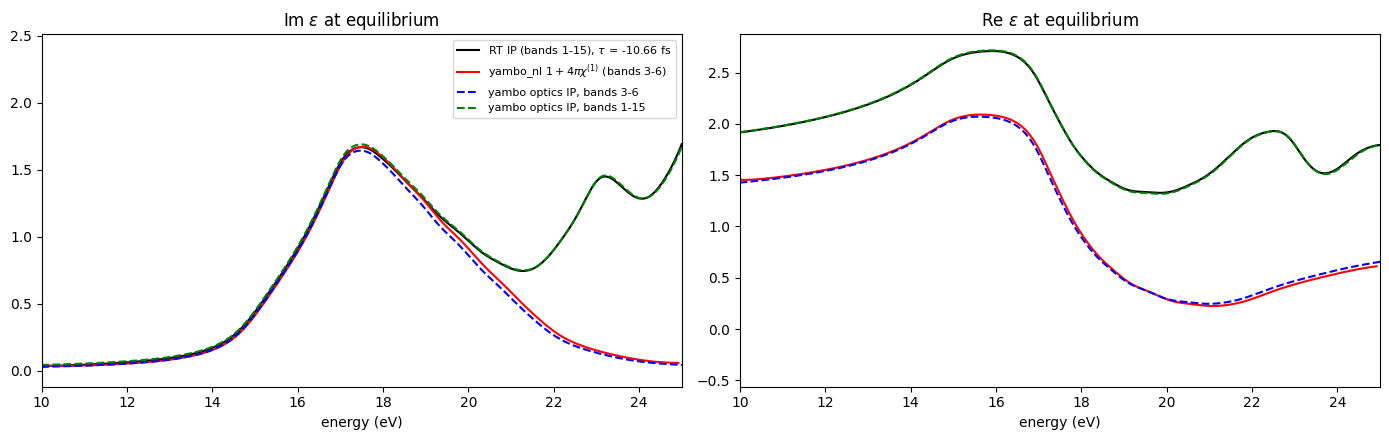

In [7]:
from scipy.optimize import minimize_scalar

def invint_correction(freqs, chi, dt=0.01):
    # removes the effects of the INVINT integrator with time step dt (fs) from chi (last axis on the grid freqs, eV, of
    # the output polarization): chi(w_eff) exp(-i w_eff dt/2), with w_eff = (2 hbar/dt) arctan(w dt/2 hbar)
    # (red shift of the resonances and delay dt/2 of the fields)
    hb = Const.Planck_reduced_ev_fs
    weff = 2*hb/dt*np.arctan(freqs*dt/(2*hb))
    chi = np.asarray(chi)*np.exp(-1j*freqs/hb*dt/2)
    out = [np.interp(weff,freqs,y.real)+1j*np.interp(weff,freqs,y.imag) for y in chi.reshape(-1,chi.shape[-1])]
    return np.array(out).reshape(chi.shape)

def best_shift(x, y, ref_x, ref_y, erange):
    # rigid shift (eV, > 0 to the right) of y(x) that minimizes the distance from ref_y(ref_x) in erange
    g = x[(x>=erange[0])&(x<=erange[1])]
    t = np.interp(g,ref_x,ref_y)
    return minimize_scalar(lambda a: np.sum((np.interp(g-a,x,y)-t)**2),bounds=(-1,1),method='bounded').x

def load_ip_optics(bands, folder='kx16_nb100_NoTr_E100'):
    # energy (eV) and eps of the IP yambo optics run with the given bands
    d = np.loadtxt(glob.glob(os.path.join(folder,'ip-optics-bands_%s-damp_0.6'%bands,'o-*.eps_q1_ip'))[0])
    return d[:,0], d[:,2]+1j*d[:,1]
ip_optics = {b: load_ip_optics(b) for b in ['3-6','1-15']}

eps_ref = rt_ip['eps'][0]
chi1_c = invint_correction(freqs,chi1_sin)   # corrected linear response of the yambo_nl runs
eps_nl = 1+4*np.pi*chi1_c

fig,axes = plt.subplots(1,2,figsize=(14,4.5))
for ax,part,lab in zip(axes,[np.imag,np.real],['Im','Re']):
    ax.plot(rt_ip['energy'],part(eps_ref),'k',label=r'RT IP (bands 1-15), $\tau$ = %.2f fs'%rt_ip['tau'][0])
    ax.plot(freqs,part(eps_nl),'r',label=r'yambo_nl $1+4\pi\chi^{(1)}$ (bands 3-6)')
    for (b,(x,e)),st in zip(ip_optics.items(),['b--','g--']):
        ax.plot(x,part(e),st,label='yambo optics IP, bands %s'%b)
    ax.set_xlim(10,25)
    ax.set_xlabel('energy (eV)')
    ax.set_title(r'%s $\epsilon$ at equilibrium'%lab)
axes[0].legend(fontsize=8)
plt.tight_layout()
curves = [('yambo_nl',freqs,eps_nl)] + [('optics %s'%b,x,e) for b,(x,e) in ip_optics.items()]
for lab,x,y in curves:
    print('Im eps, %-16s: shift of the edge (12-17.3 eV) towards RT %6.3f eV, towards optics 3-6 %6.3f eV'%(
          lab,best_shift(x,y.imag,rt_ip['energy'],eps_ref.imag,(12,17.3)),best_shift(x,y.imag,*ip_optics['3-6'][0:1],ip_optics['3-6'][1].imag,(12,17.3))))

## Transient absorption from the non-linear $\chi$

The two descriptions are linked by the following equation
\begin{eqnarray}
\chi^{neq,(1)}[E_P](\omega) &=& \chi^{(1)}(\omega;\omega) + \nonumber \\
&+& \left[ \chi^{(2)}(\omega;\omega_P,\omega-\omega_P)\frac{E_{p}(\omega-\omega_P)}{E_p(\omega)} + 
\chi^{(2)}(\omega;-\omega_P,\omega+\omega_P)\frac{E_{p}(\omega+\omega_P)}{E_p(\omega)}
\right]E_{P}(\omega_P)  + \nonumber \\ &+&\left[   
\chi^{(3)}(\omega;\omega_P,\omega_P,\omega-2\omega_P)\frac{E_{p}(\omega-2\omega_P)}{E_p(\omega)} + 
\chi^{(3)}(\omega;\omega_P,-\omega_P,\omega) + \right. \nonumber \\ &&\left.
\chi^{(3)}(\omega;-\omega_P,-\omega_P,\omega+2\omega_P)\frac{E_{p}(\omega+2\omega_P)}{E_p(\omega)}
\right]E^2_{P}(\omega_P)
\end{eqnarray}

### Formula used for $\delta\chi^{neq}$

The MPPI key `Xn_frequency_mixing(...).compute_Xn()[0][(1,m)]` at the probe frequency $\omega$ is the ratio between the
component of $P$ at $\omega+m\omega_P$ and the product $E_p(\omega)E_P(\pm\omega_P)^{|m|}$ of the field amplitudes, with
$E(t) = \sum_n E(\omega_n)e^{-i\omega_n t}$, $E(-\omega) = E(\omega)^*$, and $E(\omega) = (iE_0/2)e^{i\omega t_0}$ for a
sine field $E_0\sin(\omega(t-t_0))$ (Boyd, Sec. 1.3; the keys include the degeneracy factors, $\chi_{(1,\pm2)} = 3\chi^{(3)}$).

Only the third order terms are kept: the second order terms $\chi_{(1,\pm1)}$ vanish by symmetry in LiF (in our runs
they are an error of the k discretization, see `NL-Chi_Analysis.ipynb`). The change of the response at the frequency
$\omega$ of the transient spectrum is

$$
\delta\chi(\omega) = \chi_{(1,1,-1)}(\omega)|E_P(\omega_P)|^2
+ \chi_{(1,2)}(\omega-2\omega_P)\frac{E_p(\omega-2\omega_P)}{E_p(\omega)}E_P(\omega_P)^2
+ \chi_{(1,-2)}(\omega+2\omega_P)\frac{E_p(\omega+2\omega_P)}{E_p(\omega)}E_P(-\omega_P)^2 ,
\qquad \chi_{(1,1,-1)} = \frac{\chi_{(1,0)}-\chi^{(1)}}{E_{0P,run}^2/4}
$$

($E_{0P,run}$ is the pump amplitude of the yambo_nl run). It holds for a monochromatic pump. The fields of the RT runs:

- **probe**: delta kick at $t_p$, $E_p(\omega)\propto e^{i\omega t_p}$, so $E_p(\omega\mp2\omega_P)/E_p(\omega) =
  e^{\mp2i\omega_P t_p}$;
- **pump**: a pulse. For QSFIELD with phase 90° yambo (`RT_small_a`) sets the vector potential
  $A(t)\propto f(t)\cos(\omega_P(t-t_P))$, with the envelope $f(t) = e^{-(t-t_P)^2/2\sigma^2}$ centered at $t_P$, and
  $E = -\dot A$, i.e. $E_P(t) = -E_{0P}f(t)[\sin(\omega_P(t-t_P)) + (t-t_P)\cos(\omega_P(t-t_P))/\omega_P\sigma^2]$
  (checked in `RT_small_a.F` and `RT_Ext_fields.F` of Lumen). The second term, the derivative of the envelope, is
  $\sim$12% of the field at $|t-t_P|$ = 3 fs and acts on the phases of the $(1,\pm2)$ terms as a pump frequency larger by
  $\hbar/\omega_P\sigma^2\simeq$ 0.03 eV: we neglect it, $E_P(t) = -E_{0P}f(t)\sin(\omega_P(t-t_P))$.

**Quasi-monochromatic approximation.** The signal of the delta probe is built in a short time after $t_p$: the
smoothing of 0.6 eV damps the probe polarization in $\hbar/0.6$ eV $\simeq$ 1.1 fs, shorter than $\sigma$. In this
time the envelope is nearly constant, $f(t)\simeq f(t_p) = e^{-\tau^2/2\sigma^2}$ with the delay $\tau = t_p - t_P$, so
the pump acts on the probe response as a monochromatic sine field of amplitude $E_{0P}f(\tau)$ with phase reference
$t_P$. With the convention above its amplitude is $E_P(\omega_P) = -(iE_{0P}f(\tau)/2)\,e^{i\omega_P t_P}$, hence

$$
|E_P(\omega_P)|^2 = \frac{E_{0P}^2}{4}e^{-\tau^2/\sigma^2} \equiv |E_P(\tau)|^2, \qquad
E_P(\pm\omega_P)^2 = -|E_P(\tau)|^2\,e^{\pm2i\omega_P t_P} .
$$

The minus sign is the square of $i$, i.e. it comes from the sine shape of the pump (for a cosine pump it would be +);
the global sign of the field does not matter. Combining the phases of the probe and of the pump,
$e^{\mp2i\omega_P(t_p-t_P)} = e^{\mp2i\omega_P\tau}$:

$$
\delta\chi(\omega,\tau) = |E_P(\tau)|^2\left[\chi_{(1,1,-1)}(\omega) - \chi_{(1,2)}(\omega-2\omega_P)\,e^{-2i\omega_P\tau}
- \chi_{(1,-2)}(\omega+2\omega_P)\,e^{2i\omega_P\tau}\right]
$$

and $\Delta\epsilon(\omega,\tau) = 4\pi\,\delta\chi(\omega,\tau)$ is compared with $\epsilon(\omega,\tau)-\epsilon_{ref}(\omega)$
of the RT runs. The phases depend only on the delay: the term $\chi_{(1,1,-1)}$ does not oscillate with $\tau$, the
$(1,\pm2)$ terms oscillate with period $\pi/\omega_P$ = 1.33 fs.

### Frequency grids

The key $(1,m)$ computed at the probe frequency $\omega'$ of the runs is the response at $\omega'+m\omega_P$. In the
spectrum at the frequency $\omega$ the three terms are therefore read at $\omega' = \omega$ ($\chi_{(1,1,-1)}$),
$\omega-2\omega_P$ ($\chi_{(1,2)}$) and $\omega+2\omega_P$ ($\chi_{(1,-2)}$). Each key alone covers a shifted range of
output frequencies, but $\delta\chi(\omega)$ is defined only where all three terms are available:
$\omega\in[\omega'_{min}+2\omega_P,\ \omega'_{max}-2\omega_P]$ = 13.10-21.82 eV for the probe window 10.000-24.919 eV.
The probe step of the runs is $\omega_P/16$ = 0.096875 eV, so $2\omega_P$ = 32 steps and the shifted frequencies are
exactly on the grid (an index shift, no interpolation). A wider range of $\omega$ needs a wider probe window.

Other ingredients of the comparison with the RT runs:

- **pump frequency**: 1.55 eV in the yambo_nl runs, 1.56 eV in the RT runs. The keys are read with the shift $2\omega_P$
  of the runs (3.10 instead of 3.12 eV, negligible with a broadening of 0.6 eV), the phases $e^{\mp2i\omega_P\tau}$ use
  the RT pump frequency (0.02 eV give 0.4 rad at 7 fs);
- **pump amplitude**: yambo intensities are in kW/cm$^2$ (the `kWLm2` of the inputs; $E_0 = \sqrt{4\pi I/c}$ in atomic
  units, 1e6 kW/cm$^2$ give the $E_0$ = 1.194e-4 au of our runs). The RT pump, 6e9 kW/cm$^2$, has $E_{0P}$ = 9.25e-3 au:
  intensity 6000 times the one of our runs, far beyond the range of the pump intensity test (fifth order corrections
  $\propto I_P$, 1-2% of the cubic terms at 1.6e7 kW/cm$^2$), so higher orders can be relevant in the RT runs;
- **bands**: 3-6 in our runs, 1-15 in the RT IP runs: transitions to the bands above 6 (from $\sim$19-20 eV) are missing
  in our $\chi$.

In [8]:
def dchi_neq(freqs, chi, chi1, EP_run, taus, E0P, sigma=None, wP=None, wP_phase=None):
    '''
    Pump induced change of the probe response (third order terms, MPPI keys), for a delta probe and a sine pump:
        dchi(w,tau) = |E_P(tau)|^2 [x3(w) - chi_(1,2)(w-2wP) exp(-2i wP tau) - chi_(1,-2)(w+2wP) exp(2i wP tau)]
    with x3 = (chi_(1,0)-chi1)/(EP_run^2/4) and |E_P(tau)|^2 = E0P^2/4 exp(-tau^2/sigma^2).

    Args:
        freqs : probe frequencies of the runs (eV), uniform grid with 2 wP equal to a multiple of the step
        chi : keys of Xn_frequency_mixing.compute_Xn on the grid freqs ((1,0), (1,2), (1,-2))
        chi1 : linear response on the grid freqs (e.g. first harmonic of the sine runs)
        EP_run : pump amplitude E0 of the yambo_nl run (au)
        taus : delays probe - pump maximum (fs)
        E0P : pump amplitude E0 to be used (au)
        sigma : width of the gaussian envelope of the pump field (fs), None for a monochromatic pump
        wP : pump frequency of the runs (eV), it fixes the shifted grids
        wP_phase : pump frequency (eV) in the phases exp(-+2i wP tau), default wP

    Returns:
        w (eV) : frequencies of the spectrum, freqs[n:-n] with n = 2wP/step
        dchi : array (len(taus), len(w)) in au (Delta eps = 4 pi dchi)
    '''
    if wP_phase is None: wP_phase = wP
    step = freqs[1]-freqs[0]
    n = int(round(2*wP/step))
    assert abs(n*step-2*wP) < 1e-3*step, '2 wP is not a multiple of the frequency step'
    taus = np.atleast_1d(taus)[:,None]
    x3 = (chi[(1,0)]-chi1)/(EP_run**2/4)
    phase = 2*wP_phase/Const.Planck_reduced_ev_fs*taus
    env2 = 1. if sigma is None else np.exp(-(taus/sigma)**2)
    dchi = E0P**2/4*env2*(x3[n:-n] - chi[(1,2)][:-2*n]*np.exp(-1j*phase) - chi[(1,-2)][2*n:]*np.exp(1j*phase))
    return freqs[n:-n], dchi

# pump of the RT runs: amplitude from the ratio of the intensities (kW/cm^2) w.r.t. the yambo_nl run (1e6 kW/cm^2)
pump_rt = rt_ip['pump']
E0P_rt = EP*np.sqrt(pump_rt['intensity']/1e6)
w, dchi = dchi_neq(freqs,chi_freqmix,chi1_sin,EP,rt_ip['tau'],E0P_rt,sigma=pump_rt['sigma'],
                   wP=omega_P*Const.HaToeV,wP_phase=pump_rt['freq'])
deps_chi = 4*np.pi*invint_correction(w,dchi)   # INVINT correction at the frequency of the spectrum
deps_rt = np.array([np.interp(w,rt_ip['energy'],d.real)+1j*np.interp(w,rt_ip['energy'],d.imag)
                    for d in rt_ip['eps']-rt_ip['eps'][0]])
print('omega %.3f-%.3f eV (%d points), E0P of the RT pump %.3e au (%.0f times the yambo_nl one)'%(w[0],w[-1],len(w),E0P_rt,E0P_rt/EP))

omega 13.100-21.819 eV (91 points), E0P of the RT pump 9.246e-03 au (77 times the yambo_nl one)


Comparison at three delays around the pump maximum (black: RT, red: from the $\chi$) and maps of $\Delta$Im $\epsilon$
vs the delay (same color scale).

RT         max |Delta eps| (all delays): 13.1-17.5 eV 0.107, 17.5-21.8 eV 0.099
chi3       max |Delta eps| (all delays): 13.1-17.5 eV 0.155, 17.5-21.8 eV 0.091
           rel. rms distance from RT in 13.6-17.5 eV (all delays): 0.677


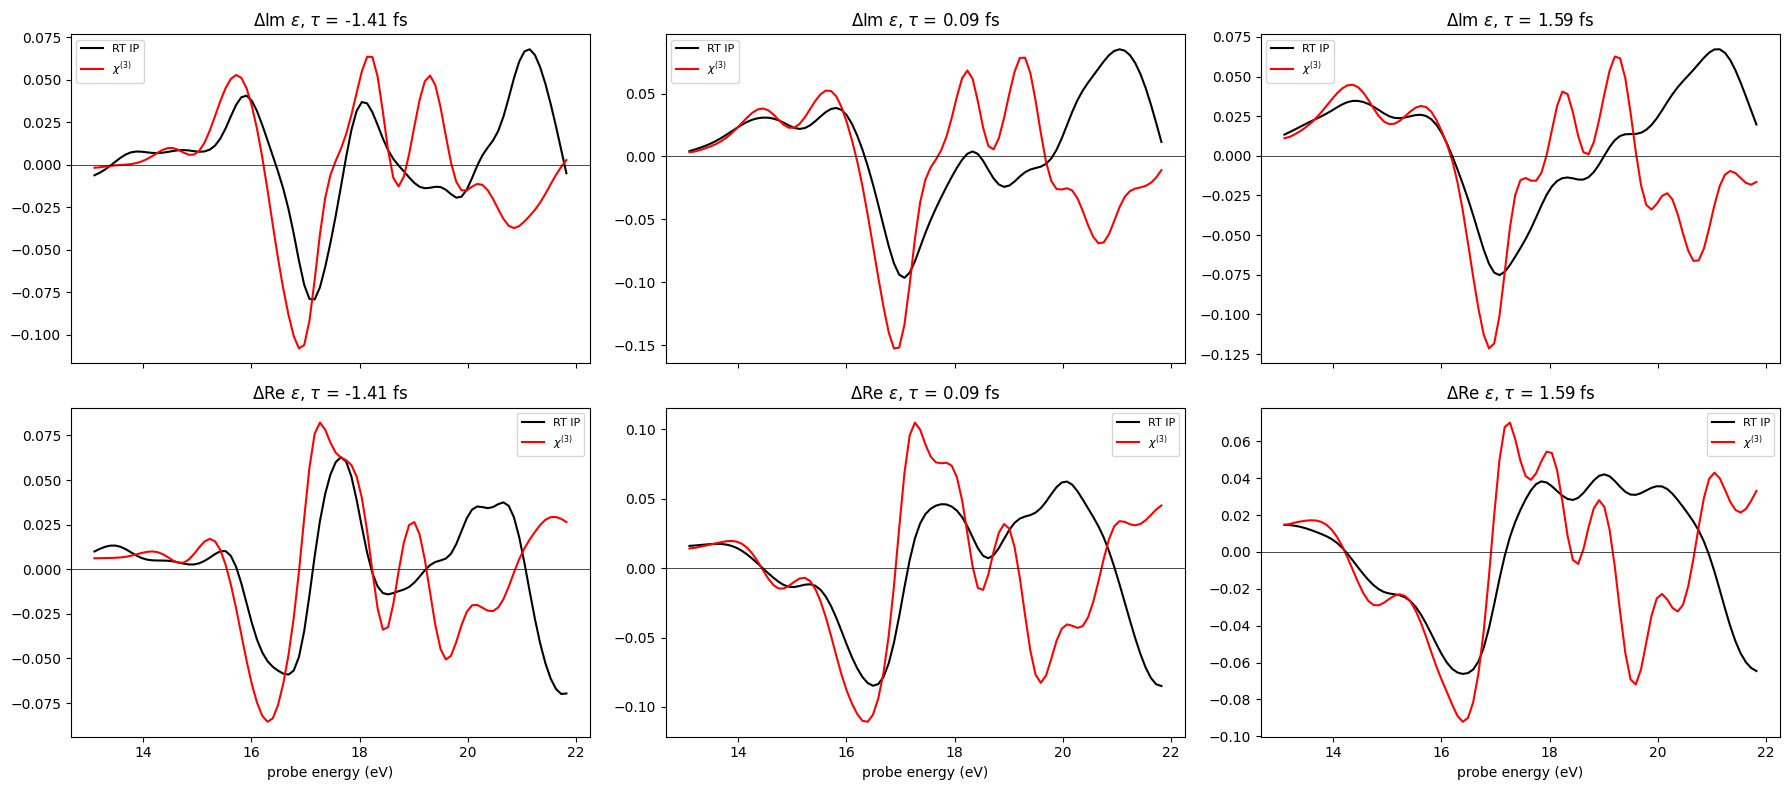

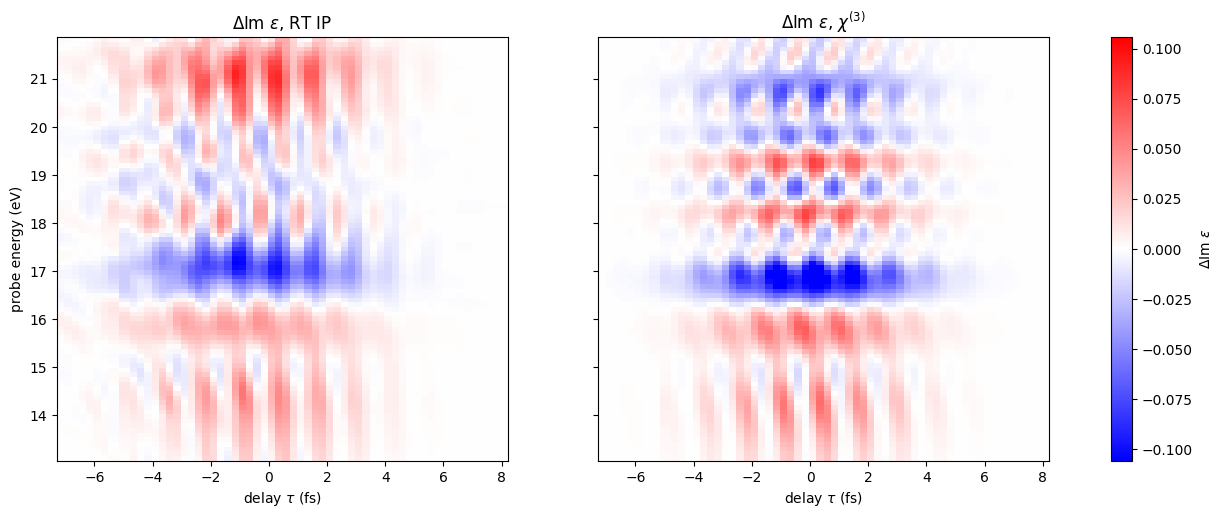

In [9]:
taus_cmp = [-1.4,0.1,1.6]
fig,axes = plt.subplots(2,len(taus_cmp),figsize=(18,8),sharex=True)
for k,t in enumerate(taus_cmp):
    i = np.argmin(np.abs(rt_ip['tau']-t))
    for row,(part,lab) in enumerate([(np.imag,'Im'),(np.real,'Re')]):
        ax = axes[row,k]
        ax.plot(w,part(deps_rt[i]),'k',label='RT IP')
        ax.plot(w,part(deps_chi[i]),'r',label=r'$\chi^{(3)}$')
        ax.axhline(0,color='k',lw=0.5)
        ax.set_title(r'$\Delta$%s $\epsilon$, $\tau$ = %.2f fs'%(lab,rt_ip['tau'][i]))
        ax.legend(fontsize=8)
for ax in axes[-1]: ax.set_xlabel('probe energy (eV)')
plt.tight_layout()

it = np.arange(1,len(rt_ip['tau']))
vmax = np.abs(deps_rt[it].imag).max()
fig,axes = plt.subplots(1,2,figsize=(16,5.5),sharey=True)
for ax,d,lab in zip(axes,[deps_rt,deps_chi],['RT IP',r'$\chi^{(3)}$']):
    pc = ax.pcolormesh(rt_ip['tau'][it],w,d[it].imag.T,cmap='bwr',norm=TwoSlopeNorm(0,-vmax,vmax),shading='nearest')
    ax.set_title(r'$\Delta$Im $\epsilon$, %s'%lab)
    ax.set_xlabel(r'delay $\tau$ (fs)')
axes[0].set_ylabel('probe energy (eV)')
fig.colorbar(pc,ax=axes,label=r'$\Delta$Im $\epsilon$')

m = w < 17.5
sel = (w >= 13.6) & (w <= 17.5)
for lab,d in [('RT',deps_rt),('chi3',deps_chi)]:
    print('%-10s max |Delta eps| (all delays): 13.1-17.5 eV %.3f, 17.5-21.8 eV %.3f'%(lab,np.abs(d[it][:,m]).max(),np.abs(d[it][:,~m]).max()))
    if lab != 'RT':
        print('%-10s rel. rms distance from RT in 13.6-17.5 eV (all delays): %.3f'%('',
              np.linalg.norm(d[it][:,sel]-deps_rt[it][:,sel])/np.linalg.norm(deps_rt[it][:,sel])))

**Comparison RT IP vs $\chi^{(3)}$ (no free parameters).** Below $\sim$17.5 eV the reconstruction from the $\chi$
reproduces the RT spectra: the bleach at 17 eV, the positive band at 14-16 eV, the oscillations with period
$\pi/\omega_P$ = 1.33 fs in phase with the RT ones and the decay with the pump envelope. The bleach at 17 eV is $\sim$1.5
times larger than in the RT runs (maxima printed above). Above 17.5 eV the shapes differ.

**Equilibrium.** The INVINT correction (the phase $\omega dt/2$ is the larger effect) brings the yambo_nl $\chi^{(1)}$ onto
the `yambo` optics spectrum with the same bands (edge within 0.01 eV, 2% on $\epsilon$; 0.8% for the delta run), and the
optics spectrum with the bands 1-15 coincides with the RT reference (edge within 0.03 eV: yambo 5.3 and Lumen agree).
Without the correction the edge was 0.26 eV below the RT one. The bands 7-15 move the edge by only 0.07 eV, but they add
the absorption above 19 eV and $\sim$0.5 to Re $\epsilon$.

**Residual shift.** A rigid shift of the reconstructed $\Delta\epsilon$ to the right still improves the agreement in
13.6-17.5 eV (best shift 0.22 eV, rel. rms distance 0.68 $\to$ 0.44; before the correction 0.34 eV from 0.93). Unlike
the equilibrium one it depends on the pump envelope: 0.15-0.27 eV for $e^{-\tau^2/\sigma^2}>0.5$, 0.04-0.14 eV in the tail
after the pump, and near the maximum the RT signal is smaller than the $\chi^{(3)}$ one (ratio 0.6-0.85). This is what one
expects beyond third order: a pump induced shift $\Delta$ of the edge gives
$\epsilon(\omega-\Delta)-\epsilon(\omega)\simeq-\Delta\,\epsilon'(\omega-\Delta/2)$, the perturbative $-\Delta\epsilon'(\omega)$
moved by $\Delta/2$ and reduced when $\Delta$ is comparable with the 0.6 eV broadening; the RT pump intensity is 1500 times
the highest one of our perturbative tests (4e6 kW/cm$^2$). Checked with our RT runs at lower pump intensity (next section). Still
open: the bands above 6 in the cubic terms and their k convergence (16-21 eV).

## Our RT runs: bands and pump intensity

RT pump-probe runs with `yambo_nl` and the same setup of the IP runs of D. Sangalli (section "RT pump-probe runs with the
setup of D. Sangalli" of `YamboNL_Analysis.ipynb`, folder `kx16_nb100_NoTr_E100/rt-ip-*`): CRANKNIC 3 as, 40 fs, no
damping, delta probe at $t_p$, QSFIELD PHPI90 5SIGMA pump at 1.56 eV ($t_P$ = 15.909 fs). For each run
$\Delta\epsilon = \epsilon[P_{Pp}-P_P] - \epsilon_{eq}$, with the pump-only run of the same pump and the probe-only run
of the same bands as reference (`Linear_Response`, Lorentzian smoothing 0.6 eV as in ypp). Runs: bands 3-6 with pump
6e9, 6e8, 6e7 kW/cm$^2$ at $t_p$ = 13, 14.5, 16, 17.5, 19 fs; bands 1-15 with 6e9 at 16 fs and 6e7 at 14.5, 16, 17.5 fs.

First the checks of the setup: our run with the bands 1-15 and 6e9 at $t_p$ = 16 fs against the run of D. Sangalli
(raw databases, same analysis), and the probe-only spectra against the `yambo` optics ones.

In [10]:
nl_rt_dir = 'kx16_nb100_NoTr_E100'
t_probes_nl = [13.0,14.5,16.0,17.5,19.0]
davide_dir = '/work/sangalli/simulations/LiF/yambo/e80_kx6_pbe_sr/kx16_nb100/NoTr_E100'

def rt_id(bands, pump_int=None, t_probe=None):
    # run id of the RT runs of YamboNL_Analysis.ipynb (bands as a string, e.g. '3-6')
    idd = 'rt-ip-bands_%s'%bands
    if pump_int is not None: idd += '-EP_%s'%('%.0e'%pump_int).replace('e+0','e')
    if t_probe is not None: idd += '-tp_%.2f'%t_probe
    return idd + '-' + {(True,True):'Pp',(True,False):'P',(False,True):'p'}[(pump_int is not None,t_probe is not None)]

def load_nl(path):
    return P.YamboNLDBParser(os.path.join(path,'ndb.Nonlinear'),verbose=False)

def nl_eps(run, ref=None, eta=0.6):
    # energy (eV) and eps along x from the delta probe of the run, minus the polarization of ref (pump only)
    return O.Linear_Response(np.array(run.IO_TIME_points),run.Polarization[0],run.Efield[0],
                             pol_ref=None if ref is None else ref.Polarization[0],eta=eta)

def nl_delay(run):
    # tau = t_p - t_P (fs), t_P = maximum of the QSFIELD 5SIGMA pump (as in yambo RT_small_a)
    pump = run.Efield2[0]
    wP, sigma = pump['freq_range'][0], pump['damping']/(2*np.sqrt(2*np.log(2)))     # au, damping = FWHM
    t_P = pump['initial_time'] + np.pi/wP*np.rint(wP/np.pi*5*sigma)
    return (run.Efield[0]['initial_time']-t_P)/Const.FsToAu

on_w = lambda x, y: np.interp(w,x,y.real)+1j*np.interp(w,x,y.imag)      # complex spectrum on the grid w of dchi_neq
rel_max = lambda a, b, s: np.abs(a[s]-b[s]).max()/np.abs(b[s]).max()

# setup check vs D. Sangalli: bands 1-15, 6e9, t_p = 16 fs
dav_Pp = load_nl(davide_dir+'/sh6.0+str0.05_6E9_new/tdberry/td-ip-ber_3.0as_inv_1-15b_qsf90pi1.56_6.0E9_deph0.0eV_delta16.00fs_Pp_NL')
dav_P = load_nl(davide_dir+'/td-ip-berry_3.0as_inv_1-15b_qsf90pi1.56_6.0E9_deph0.0eV_t40fs_P_NL')
en_nl, e_ours = nl_eps(load_nl(os.path.join(nl_rt_dir,rt_id('1-15',6e9,16.0))),load_nl(os.path.join(nl_rt_dir,rt_id('1-15',6e9))))
e_dav = nl_eps(dav_Pp,dav_P)[1]
s_nl = (en_nl > 10) & (en_nl < 25)
print('bands 1-15, 6e9, t_p = 16 fs: eps ours vs D. Sangalli, max rel. difference in 10-25 eV %.1e'%rel_max(e_ours,e_dav,s_nl))

# equilibrium (probe only) with CRANKNIC 3 as vs yambo optics
eps_eq_nl = {}
for b in ['3-6','1-15']:
    eps_eq_nl[b] = nl_eps(load_nl(os.path.join(nl_rt_dir,rt_id(b,None,10.0))))[1]
    x, e = ip_optics[b]
    eo = np.interp(en_nl,x,e.real)+1j*np.interp(en_nl,x,e.imag)
    print('bands %-4s: probe-only eps vs yambo optics, max rel. difference in 10-25 eV %.1e, edge shift %.3f eV'%(
          b,rel_max(eps_eq_nl[b],eo,s_nl),best_shift(en_nl,eps_eq_nl[b].imag,x,e.imag,(12,17.3))))

bands 1-15, 6e9, t_p = 16 fs: eps ours vs D. Sangalli, max rel. difference in 10-25 eV 3.3e-07
bands 3-6 : probe-only eps vs yambo optics, max rel. difference in 10-25 eV 7.9e-03, edge shift -0.018 eV
bands 1-15: probe-only eps vs yambo optics, max rel. difference in 10-25 eV 7.3e-03, edge shift -0.026 eV


### Pump intensity and orders in the pump field

$\Delta\epsilon$ of the runs with the bands 3-6, rescaled by $6\cdot10^9/I_P$, compared with the $\chi^{(3)}$ reconstruction
(same bands) at the delay of each run. If the RT runs were in the third order regime the three intensities would give the
same rescaled spectrum. They do not, in both directions: at 6e9 the orders above the third are sizeable, at 6e7 the
spurious second order term (linear in $E_P$, the $\chi_{(1,\pm1)}$ of the k discretization, `NL-Chi_Analysis.ipynb`,
crossover intensity $\sim$2-3e7 kW/cm$^2$ on kx16) is comparable with the third order one. The orders are separated
at each frequency with the three intensities: $\Delta\epsilon(I_P) = a\,e + b\,e^2 + c\,e^4$, $e = E_P/E_P(6\cdot10^9)$,
so that $b$ is the third order term at 6e9 ($a$: second order, $c$: fifth order). Distances in 13.6-17.5 eV (rel. rms,
ratio of the maxima, best rigid shift of the $\chi^{(3)}$ spectrum, > 0 to the right).

In [11]:
def best_shift_c(y, ref, erange):
    # rigid shift (eV, > 0 to the right) of the complex spectrum y(w) that minimizes the distance from ref(w) in erange
    g = w[(w>=erange[0])&(w<=erange[1])]
    t = on_w(w,ref)[(w>=erange[0])&(w<=erange[1])]
    return minimize_scalar(lambda a: np.sum(np.abs(np.interp(g-a,w,y.real)+1j*np.interp(g-a,w,y.imag)-t)**2),
                           bounds=(-1,1),method='bounded').x

def compare(y, ref, erange=(13.6,17.5)):
    s = (w>=erange[0])&(w<=erange[1])
    return (np.linalg.norm(y[s]-ref[s])/np.linalg.norm(ref[s]), np.abs(y[s]).max()/np.abs(ref[s]).max(),
            best_shift_c(y,ref,erange))

def deps_run(bands, I, tp):
    # Delta eps on the grid w and delay of the run
    run = load_nl(os.path.join(nl_rt_dir,rt_id(bands,I,tp)))
    e = nl_eps(run,load_nl(os.path.join(nl_rt_dir,rt_id(bands,I))))[1]
    return on_w(en_nl,e-eps_eq_nl[bands]), nl_delay(run)

I_nl = [6e9,6e8,6e7]
e_nl = np.sqrt(np.array(I_nl)/6e9)
deps_nl, tau_nl = {}, {}
for b,Is,tps in [('3-6',I_nl,t_probes_nl),('1-15',[6e9],[16.0]),('1-15',[6e7],[14.5,16.0,17.5])]:
    for I in Is:
        for tp in tps: deps_nl[(b,I,tp)], tau_nl[tp] = deps_run(b,I,tp)
w_nl, dchi_nl = dchi_neq(freqs,chi_freqmix,chi1_sin,EP,[tau_nl[tp] for tp in t_probes_nl],E0P_rt,sigma=pump_rt['sigma'],
                         wP=omega_P*Const.HaToeV,wP_phase=pump_rt['freq'])
deps_chi_nl = 4*np.pi*invint_correction(w_nl,dchi_nl)
orders_nl = {}
for k,tp in enumerate(t_probes_nl):
    D = np.array([deps_nl[('3-6',I,tp)] for I in I_nl])
    orders_nl[tp] = np.linalg.solve(np.array([e_nl,e_nl**2,e_nl**4]).T,D)     # a, b, c at each frequency
    print('t_p %5.2f fs, tau %5.2f fs, chi3 vs:'%(tp,tau_nl[tp]),end='')
    for I in I_nl: print('  RT %.0e x I/6e9: %.2f %.2f %+.2f |'%(I,*compare(deps_chi_nl[k],deps_nl[('3-6',I,tp)]*6e9/I)),end='')
    a, b, c = orders_nl[tp]
    print('  3rd order b: %.2f %.2f %+.2f | max|a|/max|b| %.2f, max|c|/max|b| %.2f'%(*compare(deps_chi_nl[k],b),
          *[np.abs(x[(w>=13.6)&(w<=17.5)]).max()/np.abs(b[(w>=13.6)&(w<=17.5)]).max() for x in (a,c)]))

t_p 13.00 fs, tau -2.91 fs, chi3 vs:  RT 6e+09 x I/6e9: 0.52 0.85 +0.19 |  RT 6e+08 x I/6e9: 0.51 0.66 +0.16 |  RT 6e+07 x I/6e9: 1.13 0.64 +0.40 |  3rd order b: 0.45 0.59 +0.06 | max|a|/max|b| 0.14, max|c|/max|b| 0.46
t_p 14.50 fs, tau -1.41 fs, chi3 vs:  RT 6e+09 x I/6e9: 0.75 1.21 +0.24 |  RT 6e+08 x I/6e9: 0.25 1.08 +0.00 |  RT 6e+07 x I/6e9: 0.59 0.60 -0.15 |  3rd order b: 0.28 1.04 +0.10 | max|a|/max|b| 0.12, max|c|/max|b| 0.46
t_p 16.00 fs, tau  0.09 fs, chi3 vs:  RT 6e+09 x I/6e9: 0.69 1.62 +0.16 |  RT 6e+08 x I/6e9: 0.34 1.11 +0.12 |  RT 6e+07 x I/6e9: 0.68 0.92 +0.21 |  3rd order b: 0.19 1.16 +0.04 | max|a|/max|b| 0.08, max|c|/max|b| 0.38
t_p 17.50 fs, tau  1.59 fs, chi3 vs:  RT 6e+09 x I/6e9: 0.72 1.80 +0.22 |  RT 6e+08 x I/6e9: 0.51 1.62 +0.03 |  RT 6e+07 x I/6e9: 0.74 1.08 -0.27 |  3rd order b: 0.43 1.44 +0.13 | max|a|/max|b| 0.08, max|c|/max|b| 0.23
t_p 19.00 fs, tau  3.09 fs, chi3 vs:  RT 6e+09 x I/6e9: 0.70 1.69 +0.22 |  RT 6e+08 x I/6e9: 0.57 1.35 +0.21 |  RT 6e+07 x I

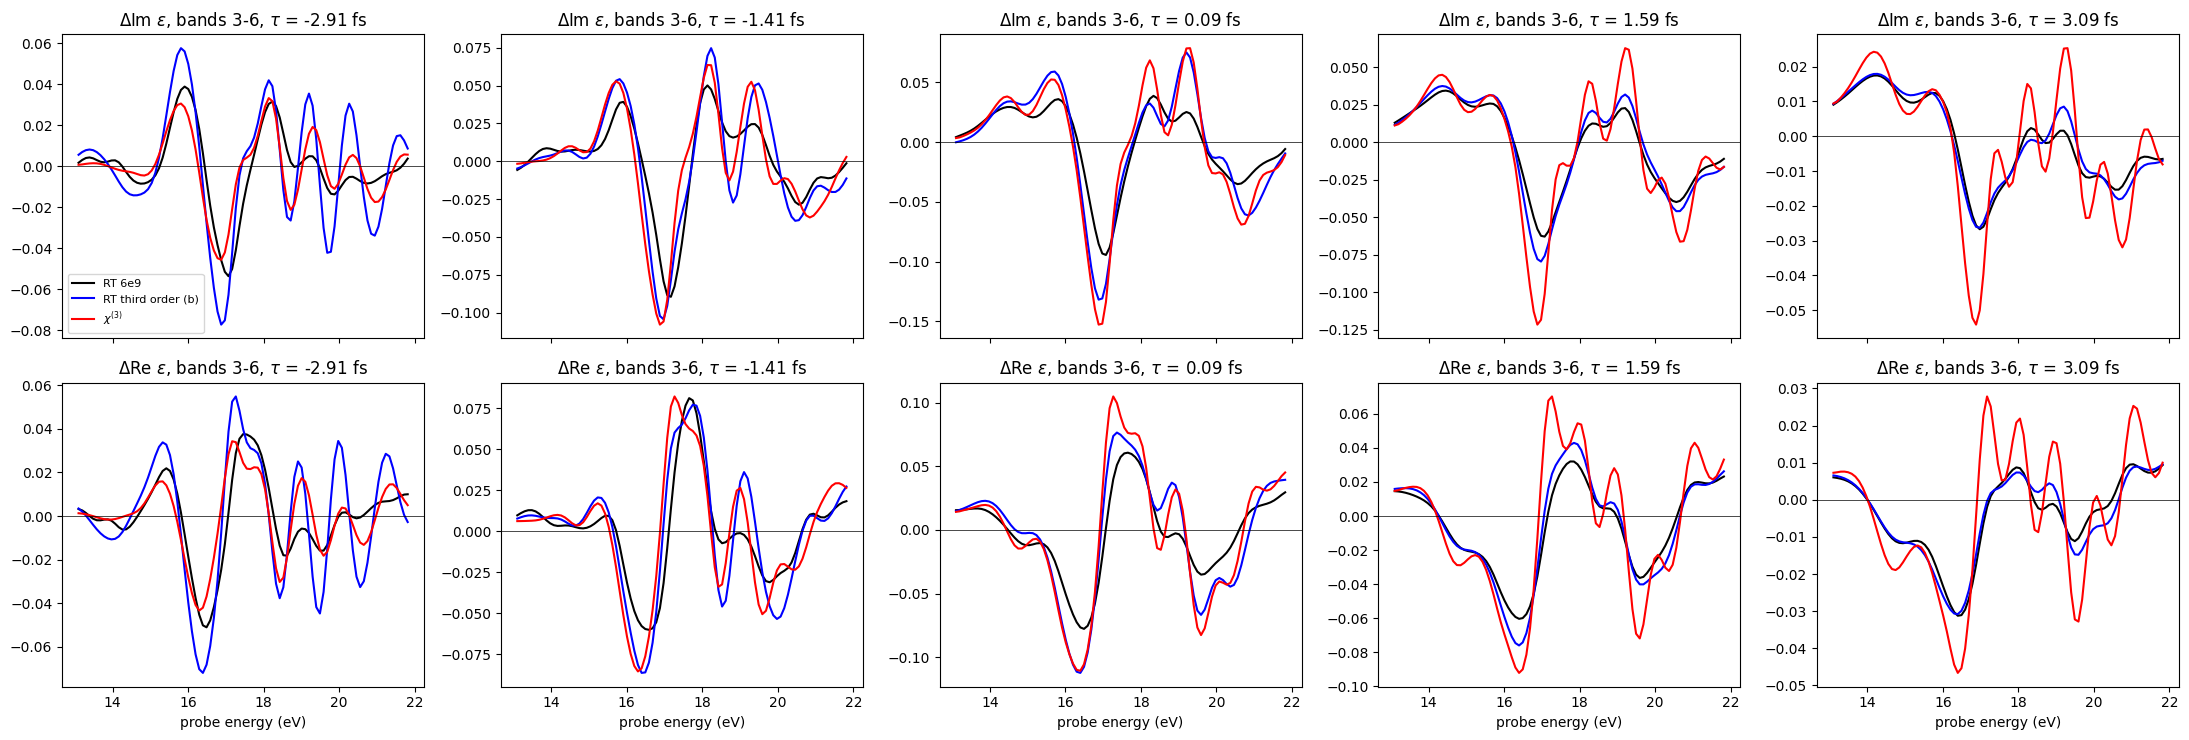

In [12]:
fig,axes = plt.subplots(2,len(t_probes_nl),figsize=(22,7.5),sharex=True)
for k,tp in enumerate(t_probes_nl):
    for row,(part,lab) in enumerate([(np.imag,'Im'),(np.real,'Re')]):
        ax = axes[row,k]
        ax.plot(w,part(deps_nl[('3-6',6e9,tp)]),'k',label='RT 6e9')
        ax.plot(w,part(orders_nl[tp][1]),'b',label='RT third order (b)')
        ax.plot(w,part(deps_chi_nl[k]),'r',label=r'$\chi^{(3)}$')
        ax.axhline(0,color='k',lw=0.5)
        ax.set_title(r'$\Delta$%s $\epsilon$, bands 3-6, $\tau$ = %.2f fs'%(lab,tau_nl[tp]))
axes[0,0].legend(fontsize=8)
for ax in axes[-1]: ax.set_xlabel('probe energy (eV)')
plt.tight_layout()

### Bands

$\Delta\epsilon$ with the bands 1-15 and 3-6 at the same pump: 6e9 ($t_p$ = 16 fs) and 6e7 ($t_p$ = 14.5, 16, 17.5 fs).

pump 6e+09, t_p 16.00 fs: bands 1-15 vs 3-6, 13.6-17.5 eV: 0.15 1.05 -0.04 | 13.6-21 eV: 1.03 1.05
pump 6e+07, t_p 14.50 fs: bands 1-15 vs 3-6, 13.6-17.5 eV: 0.03 0.99 +0.00 | 13.6-21 eV: 0.50 0.99
pump 6e+07, t_p 16.00 fs: bands 1-15 vs 3-6, 13.6-17.5 eV: 0.06 1.03 -0.01 | 13.6-21 eV: 0.62 1.03
pump 6e+07, t_p 17.50 fs: bands 1-15 vs 3-6, 13.6-17.5 eV: 0.08 1.04 -0.00 | 13.6-21 eV: 0.66 1.17


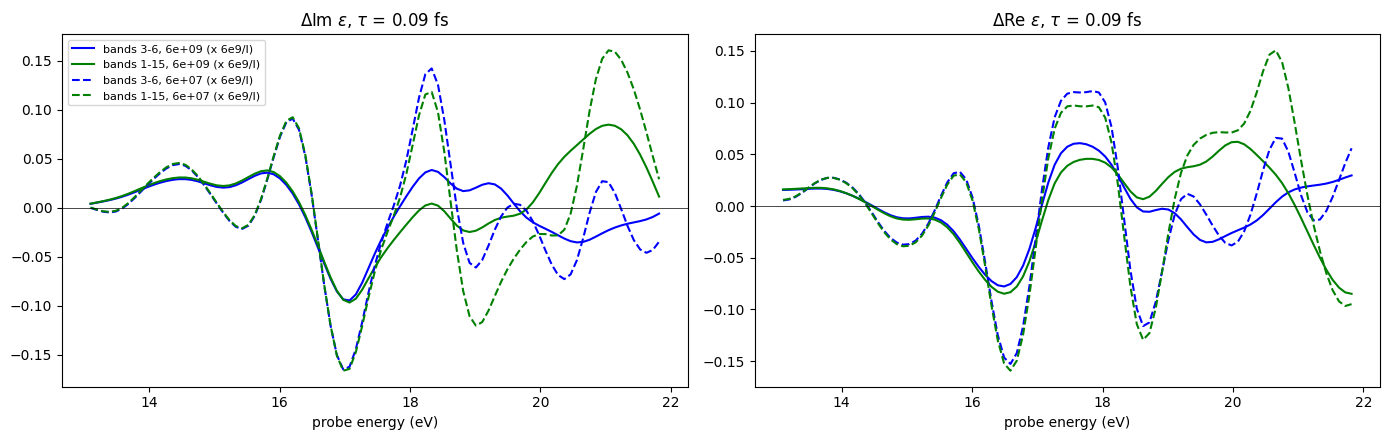

In [13]:
for I,tp in [(6e9,16.0),(6e7,14.5),(6e7,16.0),(6e7,17.5)]:
    print('pump %.0e, t_p %5.2f fs: bands 1-15 vs 3-6, 13.6-17.5 eV: %.2f %.2f %+.2f | 13.6-21 eV: %.2f %.2f'%(I,tp,
          *compare(deps_nl[('1-15',I,tp)],deps_nl[('3-6',I,tp)]),*compare(deps_nl[('1-15',I,tp)],deps_nl[('3-6',I,tp)],(13.6,21))[:2]))
fig,axes = plt.subplots(1,2,figsize=(14,4.5))
for ax,part,lab in zip(axes,[np.imag,np.real],['Im','Re']):
    for (I,st) in [(6e9,'-'),(6e7,'--')]:
        for b,col in [('3-6','b'),('1-15','g')]:
            ax.plot(w,part(deps_nl[(b,I,16.0)])*6e9/I,col+st,label='bands %s, %.0e (x 6e9/I)'%(b,I))
    ax.axhline(0,color='k',lw=0.5)
    ax.set_xlabel('probe energy (eV)')
    ax.set_title(r'$\Delta$%s $\epsilon$, $\tau$ = %.2f fs'%(lab,tau_nl[16.0]))
axes[0].legend(fontsize=8)
plt.tight_layout()

**Results of our RT runs.**

- *Setup.* Our run with the bands 1-15 and the pump 6e9 coincides with the one of D. Sangalli ($3\cdot10^{-7}$ on
  $\epsilon$): same input, Lumen 2.1.0 and yambo 5.3 agree. The probe-only spectra with CRANKNIC 3 as coincide with the
  `yambo` optics ones (0.8%, edge within 0.03 eV) for both sets of bands.
- *Bands.* In 13.6-17.5 eV the bands 1-15 and 3-6 give the same $\Delta\epsilon$ (rel. rms 0.03-0.08 at 6e7, 0.15 at
  6e9, no shift): the bands are not the origin of the differences with the $\chi^{(3)}$ there. Above 17.5 eV they
  differ strongly (rms 0.5-1 in 13.6-21 eV): the bands 7-15 matter in 18-22 eV, where the comparison with the RT of D.
  Sangalli needs $\chi$ with more bands.
- *Pump intensity.* The RT runs at 6e9 are beyond the third order: the fifth order term is 25-45% of the third order
  one near the pump maximum. At 6e7 the spurious second order term (linear in $E_P$, k discretization) is comparable
  with the third order one, so the rescaled spectra of the three intensities differ and none of them is the third order
  response. Separating the orders with the three intensities, the third order part of the RT agrees with the
  $\chi^{(3)}$ in shape and size near the pump maximum ($\tau$ = -1.41 and 0.09 fs: rel. rms 0.28 and 0.19, ratio of the
  maxima 1.04 and 1.16, shift $\le$ 0.1 eV, also above 17.5 eV with the same bands): **the residual shift of
  0.2 eV and the smaller RT bleach of the comparison with D. Sangalli come from the orders above the third**.
- *Envelope.* Away from the maximum the third order part and the $\chi^{(3)}$ still differ in size: $\chi^{(3)}$/RT =
  0.6 at $\tau$ = -2.9 fs (rising pump) and 1.4-1.7 at +1.6, +3.1 fs (falling pump), and the $\chi^{(3)}$ shows sharper
  structures in 17-21 eV. This is the limit of the quasi-monochromatic formula, which takes the pump envelope at the probe
  time: the probe polarization decays in $\hbar/0.6$ eV $\approx$ 1.1 fs while the envelope changes on $\sigma$ = 3.2 fs,
  so it feels a stronger pump before the maximum and a weaker one after it. At $\tau$ = -2.9 fs the separation of the
  orders is also less reliable (oscillations of $b$ above 18 eV). A formula with the time dependence of the envelope
  (convolution over the pump envelope) is needed for the delays away from the maximum.

### Third order RT response from the reversed pump

Runs with the bands 3-6 and the pump 6e7 kW/cm$^2$ along $-x$ (`study_rt_neg` of `YamboNL_Analysis.ipynb`). The even part
$[\Delta\epsilon(+E_P)+\Delta\epsilon(-E_P)]/2$ has no term linear in $E_P$ (the spurious second order) and, at this
intensity, a fifth order term of a few $10^{-3}$ of the third order one: it is the third order RT response, rescaled
by $6\cdot10^9/I_P$ and compared with the $\chi^{(3)}$ (same bands) and with the third order part $b$ of the fit above.
The odd part $[\Delta\epsilon(+E_P)-\Delta\epsilon(-E_P)]/2$ is the spurious second order term.

pump versor of the reversed runs: [-1.  0.  0.]
t_p 13.00 fs, tau -2.91 fs: chi3 vs even part: 0.34 0.69 +0.04 | b vs even part: 0.22 1.17 -0.02 | max|odd|/max|even| 1.56
                             13.6-21 eV: chi3 vs even part: 0.36 0.69
t_p 14.50 fs, tau -1.41 fs: chi3 vs even part: 0.17 0.95 +0.04 | b vs even part: 0.18 0.91 -0.05 | max|odd|/max|even| 0.96
                             13.6-21 eV: chi3 vs even part: 0.17 0.95


t_p 16.00 fs, tau  0.09 fs: chi3 vs even part: 0.23 1.20 +0.06 | b vs even part: 0.06 1.04 +0.02 | max|odd|/max|even| 0.74
                             13.6-21 eV: chi3 vs even part: 0.26 1.20
t_p 17.50 fs, tau  1.59 fs: chi3 vs even part: 0.41 1.44 +0.12 | b vs even part: 0.03 1.00 -0.02 | max|odd|/max|even| 0.75
                             13.6-21 eV: chi3 vs even part: 0.46 1.44
t_p 19.00 fs, tau  3.09 fs: chi3 vs even part: 0.65 1.70 +0.14 | b vs even part: 0.01 0.99 +0.00 | max|odd|/max|even| 1.00
                             13.6-21 eV: chi3 vs even part: 0.76 1.70


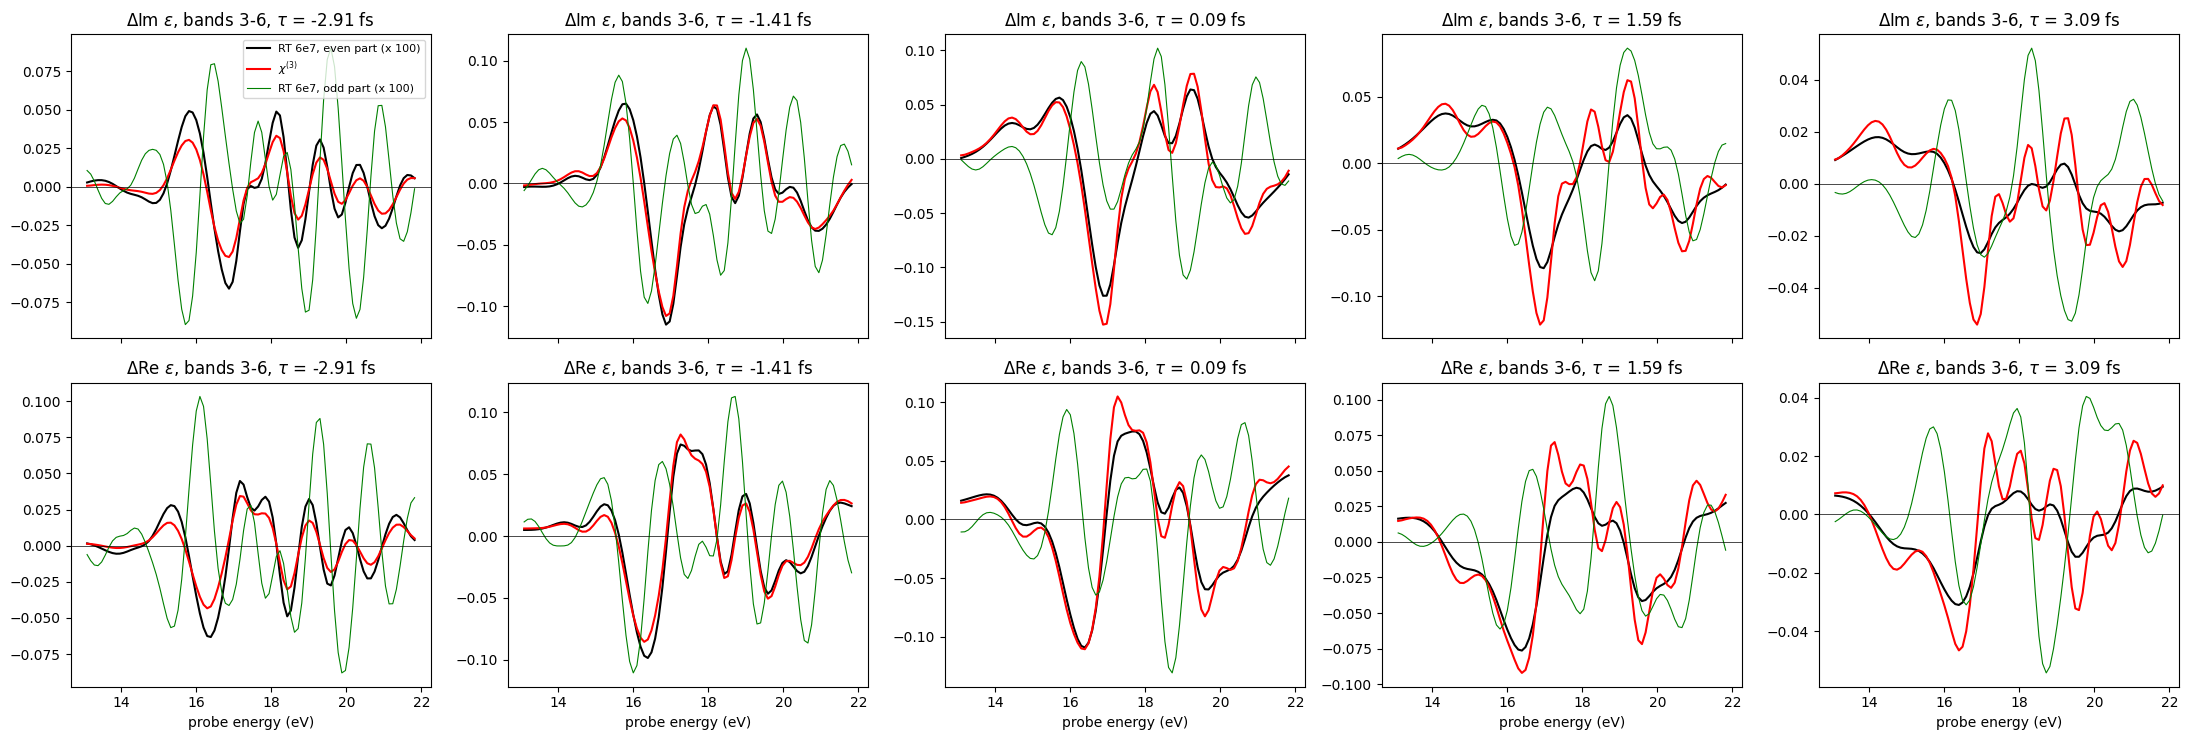

In [14]:
def rt_id_neg(bands, I, tp=None):
    return rt_id(bands,I,tp).replace('-EP_%s'%('%.0e'%I).replace('e+0','e'),'-EP_%s-neg'%('%.0e'%I).replace('e+0','e'))

def deps_run_neg(I, tp):
    run = load_nl(os.path.join(nl_rt_dir,rt_id_neg('3-6',I,tp)))
    e = nl_eps(run,load_nl(os.path.join(nl_rt_dir,rt_id_neg('3-6',I))))[1]
    return on_w(en_nl,e-eps_eq_nl['3-6'])

run = load_nl(os.path.join(nl_rt_dir,rt_id_neg('3-6',6e7,16.0)))
print('pump versor of the reversed runs:',run.Efield2[0].get('versor'))
even_nl, odd_nl = {}, {}
for k,tp in enumerate(t_probes_nl):
    dp, dm = deps_nl[('3-6',6e7,tp)], deps_run_neg(6e7,tp)
    even_nl[tp], odd_nl[tp] = (dp+dm)/2*6e9/6e7, (dp-dm)/2*6e9/6e7
    s = (w>=13.6)&(w<=17.5)
    print('t_p %5.2f fs, tau %5.2f fs: chi3 vs even part: %.2f %.2f %+.2f | b vs even part: %.2f %.2f %+.2f | max|odd|/max|even| %.2f'%(
          tp,tau_nl[tp],*compare(deps_chi_nl[k],even_nl[tp]),*compare(orders_nl[tp][1],even_nl[tp]),
          np.abs(odd_nl[tp][s]).max()/np.abs(even_nl[tp][s]).max()))
    print('                             13.6-21 eV: chi3 vs even part: %.2f %.2f'%compare(deps_chi_nl[k],even_nl[tp],(13.6,21))[:2])

fig,axes = plt.subplots(2,len(t_probes_nl),figsize=(22,7.5),sharex=True)
for k,tp in enumerate(t_probes_nl):
    for row,(part,lab) in enumerate([(np.imag,'Im'),(np.real,'Re')]):
        ax = axes[row,k]
        ax.plot(w,part(even_nl[tp]),'k',label=r'RT 6e7, even part (x 100)')
        ax.plot(w,part(deps_chi_nl[k]),'r',label=r'$\chi^{(3)}$')
        ax.plot(w,part(odd_nl[tp]),'g',lw=0.8,label=r'RT 6e7, odd part (x 100)')
        ax.axhline(0,color='k',lw=0.5)
        ax.set_title(r'$\Delta$%s $\epsilon$, bands 3-6, $\tau$ = %.2f fs'%(lab,tau_nl[tp]))
axes[0,0].legend(fontsize=8)
for ax in axes[-1]: ax.set_xlabel('probe energy (eV)')
plt.tight_layout()

**Result.** The odd part (spurious second order) is as large as the even one at 6e7 (ratio of the maxima 0.7-1.6), as
expected from the crossover intensity. The even part is the clean third order RT response:

- it coincides with the third order part $b$ of the three-intensity fit for $\tau \ge$ 0 (rel. rms 0.01-0.06), less
  well before the maximum (0.18-0.22): the fit of the previous section is validated where it was used;
- the $\chi^{(3)}$ reproduces it with **no shift** (best shift $\le$ 0.14 eV, $\le$ 0.06 eV near the maximum) and the
  right shape in the whole window 13-22 eV: rel. rms 0.17 and 0.23, ratio of the maxima 0.95 and 1.20 at $\tau$ = -1.41
  and 0.09 fs. The yambo_nl $\chi^{(3)}$ (after the INVINT correction) and the RT third order response agree;
- away from the maximum the size differs in a systematic way: $\chi^{(3)}$/RT = 0.69 at $\tau$ = -2.9 fs, 1.44 and 1.70
  at +1.6 and +3.1 fs, and after the maximum the $\chi^{(3)}$ has sharper structures in 17-21 eV than the RT. This is the
  approximation of the formula (pump envelope taken at the probe time, quasi-monochromatic pump), not of the $\chi$.

So the differences with the RT runs of D. Sangalli come from (i) the orders above the third at 6e9 (residual shift
$\sim$0.2 eV, smaller bleach), (ii) the envelope approximation away from the pump maximum, (iii) the bands above 6 in
18-22 eV.